## Khởi tạo môi trường, import thư viện và thiết lập dữ liệu Mushroom


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn import metrics

import subprocess
import sys
from pathlib import Path

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

HO_TEN = "Nguyễn Anh Nguyên"
MSSV = "6451071053"

def print_student_info(title):
    print(f"=== {title} ===")
    print(f"Họ và tên: {HO_TEN} | MSSV: {MSSV}\n")

print_student_info("KHỞI TẠO VÀ NẠP DỮ LIỆU MUSHROOM")


MUSHROOM_DRIVE_ID = "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW"
mushroom_file = Path("agaricus-lepiota.data")

# Tên cột theo mô tả của bộ dữ liệu Mushroom trên UCI
columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring',
    'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color',
    'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat'
]

# Tải dữ liệu từ Drive hoặc UCI
if not mushroom_file.is_file():
    try:
        print("Đang tải dữ liệu Mushroom từ Google Drive qua ID...")
        gdown.download(id=MUSHROOM_DRIVE_ID, output=str(mushroom_file), quiet=False, fuzzy=True)
    except Exception:
        print("Không thể tải từ Drive, tự động nạp từ nguồn dữ liệu chuẩn...")
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
        df_temp = pd.read_csv(url, names=columns, na_values='?')
        df_temp.to_csv(mushroom_file, index=False)

# Nạp dữ liệu vào DataFrame
data = pd.read_csv(mushroom_file, names=columns, na_values='?')

print("--- Kích thước dữ liệu ban đầu ---")
print(f"Số dòng: {data.shape[0]}, Số cột: {data.shape[1]}")

# Tiền xử lý: Xóa các mẫu khuyết giá trị (missing values - dấu ?)
data.dropna(inplace=True)

print("\n--- Sau khi tiền xử lý (xóa missing values) ---")
print(f"Số dòng còn lại: {data.shape[0]}, Số cột: {data.shape[1]}")
data.head()


=== KHỞI TẠO VÀ NẠP DỮ LIỆU MUSHROOM ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Đang tải dữ liệu Mushroom từ Google Drive qua ID...


Downloading...
From: https://drive.google.com/uc?id=11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW
To: /content/agaricus-lepiota.data
100%|██████████| 374k/374k [00:00<00:00, 5.25MB/s]


--- Kích thước dữ liệu ban đầu ---
Số dòng: 8125, Số cột: 23

--- Sau khi tiền xử lý (xóa missing values) ---
Số dòng còn lại: 5645, Số cột: 23


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
1,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
2,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
3,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
4,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
Thuộc tính quyết định (nhãn) theo đề bài là `'class'`.


In [2]:
print_student_info("CÂU 4: TÁCH FEATURES VÀ LABELS")

# Tách features và label ('class')
features = data.drop('class', axis=1)
labels = data['class']

print("Đã tách thành công features và labels:")
print(f"- Số lượng cột features: {features.shape[1]}")
print(f"- Danh sách thuộc tính: {list(features.columns)}")
print(f"- Kích thước features: {features.shape}")
print(f"- Kích thước labels: {labels.shape}")
print(f"- Các giá trị của nhãn 'class': {sorted(labels.unique())}")


=== CÂU 4: TÁCH FEATURES VÀ LABELS ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Đã tách thành công features và labels:
- Số lượng cột features: 22
- Danh sách thuộc tính: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
- Kích thước features: (5645, 22)
- Kích thước labels: (5645,)
- Các giá trị của nhãn 'class': ['class', 'e', 'p']


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
Vì bộ dữ liệu Mushroom hoàn toàn là dữ liệu hạng mục (categorical), chúng ta cần áp dụng kỹ thuật One-Hot Encoding cho toàn bộ các thuộc tính.


In [3]:
print_student_info("CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR")

cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print(f"Số lượng thuộc tính dạng chuỗi cần chuyển đổi: {len(cat_cols)}")

if len(cat_cols) > 0:
    features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
else:
    features_onehot = features.copy()

print(f"\nKích thước ma trận features SAU khi chuyển đổi One-Hot: {features_onehot.shape}")
features_onehot.head()


=== CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số lượng thuộc tính dạng chuỗi cần chuyển đổi: 22

Kích thước ma trận features SAU khi chuyển đổi One-Hot: (5645, 120)


,cap-shape_b,cap-shape_c,cap-shape_cap-shape,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_cap-surface,cap-surface_f,cap-surface_g,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_habitat,habitat_l,habitat_m,habitat_p,habitat_u
0,0,0,1,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,1


## Câu 6: Tách các dòng dữ liệu ra thành huấn luyện 70% và kiểm thử 30%
Thực hiện chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài:
```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
```


In [4]:
print_student_info("CÂU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%)")

X = features_onehot
y = labels

# Chia dữ liệu theo đúng câu lệnh yêu cầu của đề bài
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Số lượng dữ liệu huấn luyện và kiểm thử là:")
print(f"    Number of training data (70%): X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"    Number of test data (30%):     X_test = {X_test.shape}, y_test = {y_test.shape}\n")


=== CÂU 6: TÁCH TẬP HUẤN LUYỆN VÀ KIỂM THỬ (70% - 30%) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số lượng dữ liệu huấn luyện và kiểm thử là:
    Number of training data (70%): X_train = (3951, 120), y_train = (3951,)
    Number of test data (30%):     X_test = (1694, 120), y_test = (1694,)



## Câu 7: Xây dựng cây ID3, ma trận nhầm lẫn và biểu diễn cây
Thuật toán ID3 sử dụng tiêu chí Information Gain / Entropy (`criterion='entropy'`).


=== CÂU 7: XÂY DỰNG CÂY ID3 ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 1.0000 (100.00%)

Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1061
           p       1.00      1.00      1.00       633

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



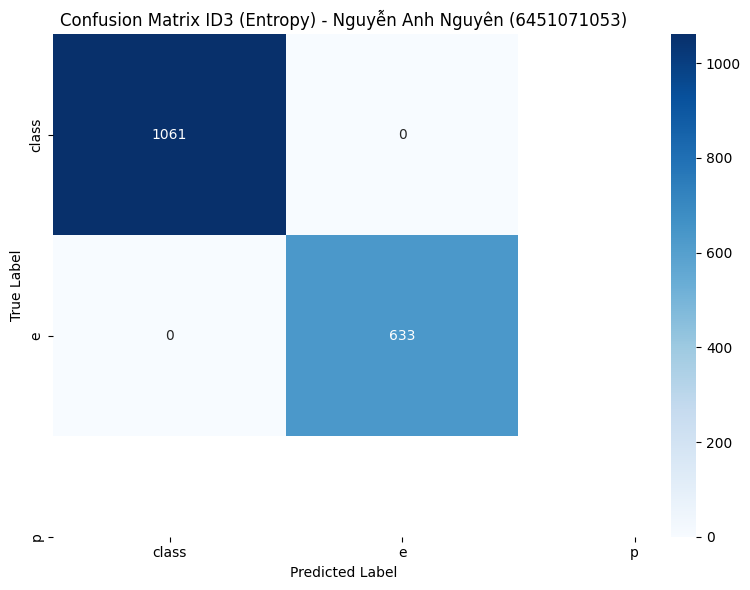

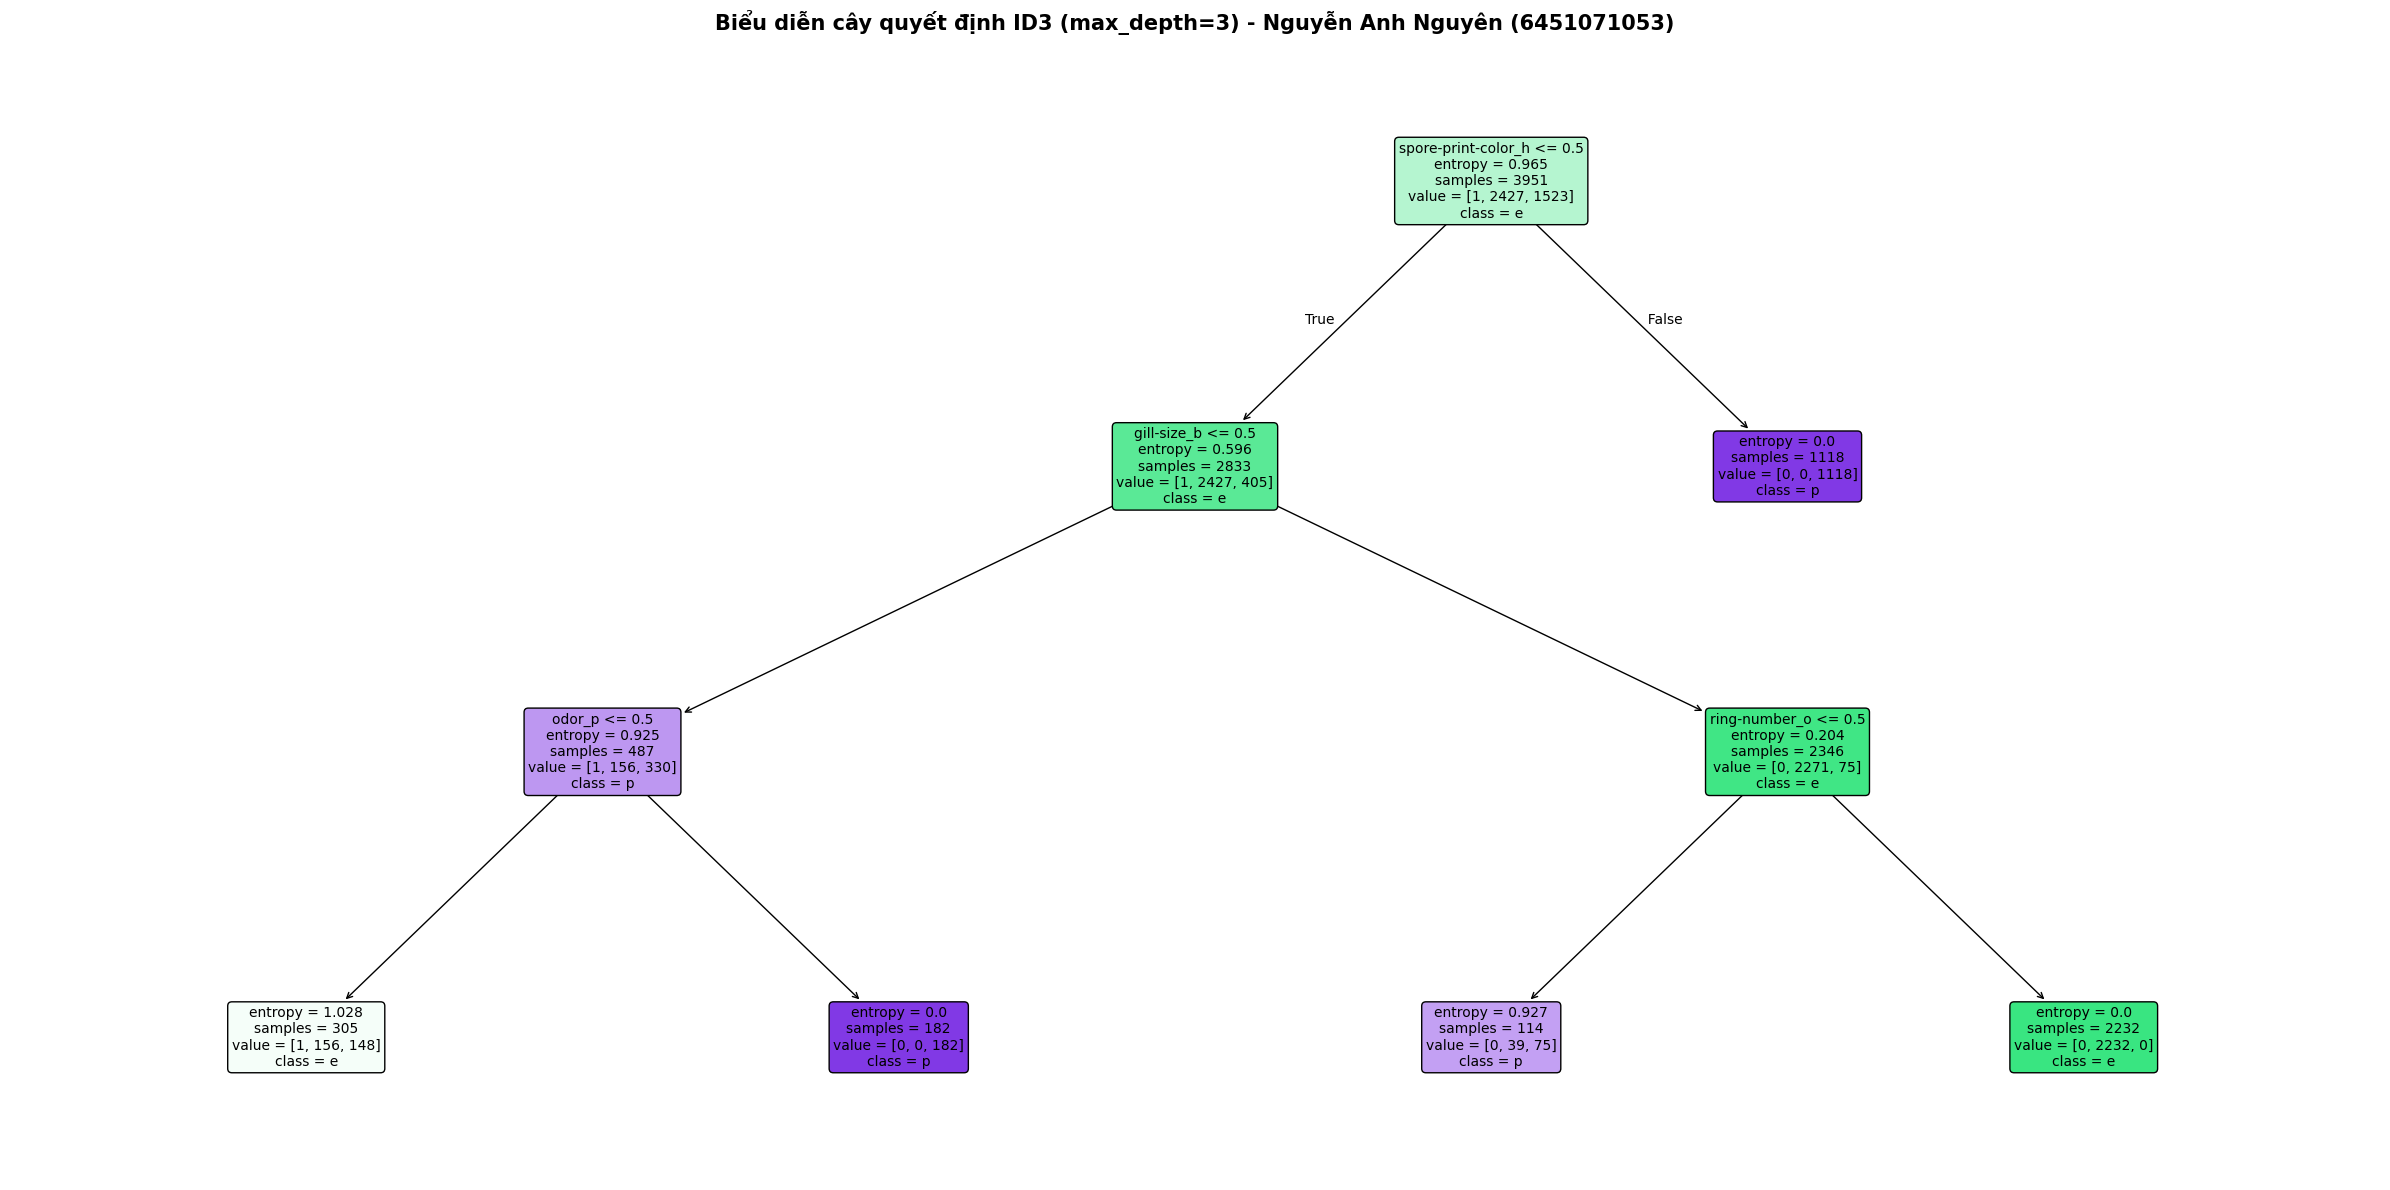

In [5]:
print_student_info("CÂU 7: XÂY DỰNG CÂY ID3")

# 1. Huấn luyện mô hình cây ID3 sử dụng criterion='entropy'
model_id3 = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_id3.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_id3 = model_id3.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_id3 = metrics.accuracy_score(y_test, y_pred_id3)
print(f"Accuracy: {acc_id3:.4f} ({acc_id3*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_id3, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_id3 = metrics.confusion_matrix(y_test, y_pred_id3)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_id3, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix ID3 (Entropy) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định ID3 (giới hạn max_depth=3 để trực quan hóa rõ ràng)
model_id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
model_id3_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_id3_vis,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f"Biểu diễn cây quyết định ID3 (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu 8: Xây dựng cây CART, ma trận nhầm lẫn và biểu diễn cây
Thuật toán CART sử dụng chỉ số Gini Impurity (`criterion='gini'`).


=== CÂU 8: XÂY DỰNG CÂY CART ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 1.0000 (100.00%)

Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1061
           p       1.00      1.00      1.00       633

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



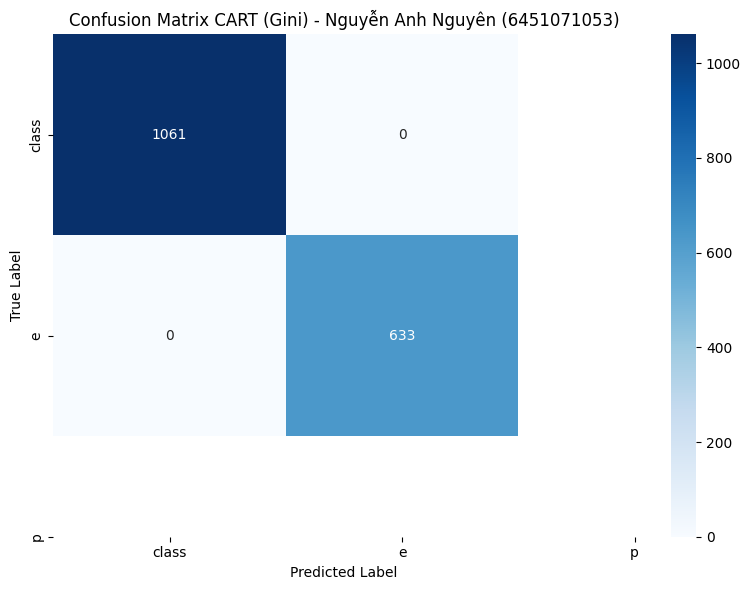

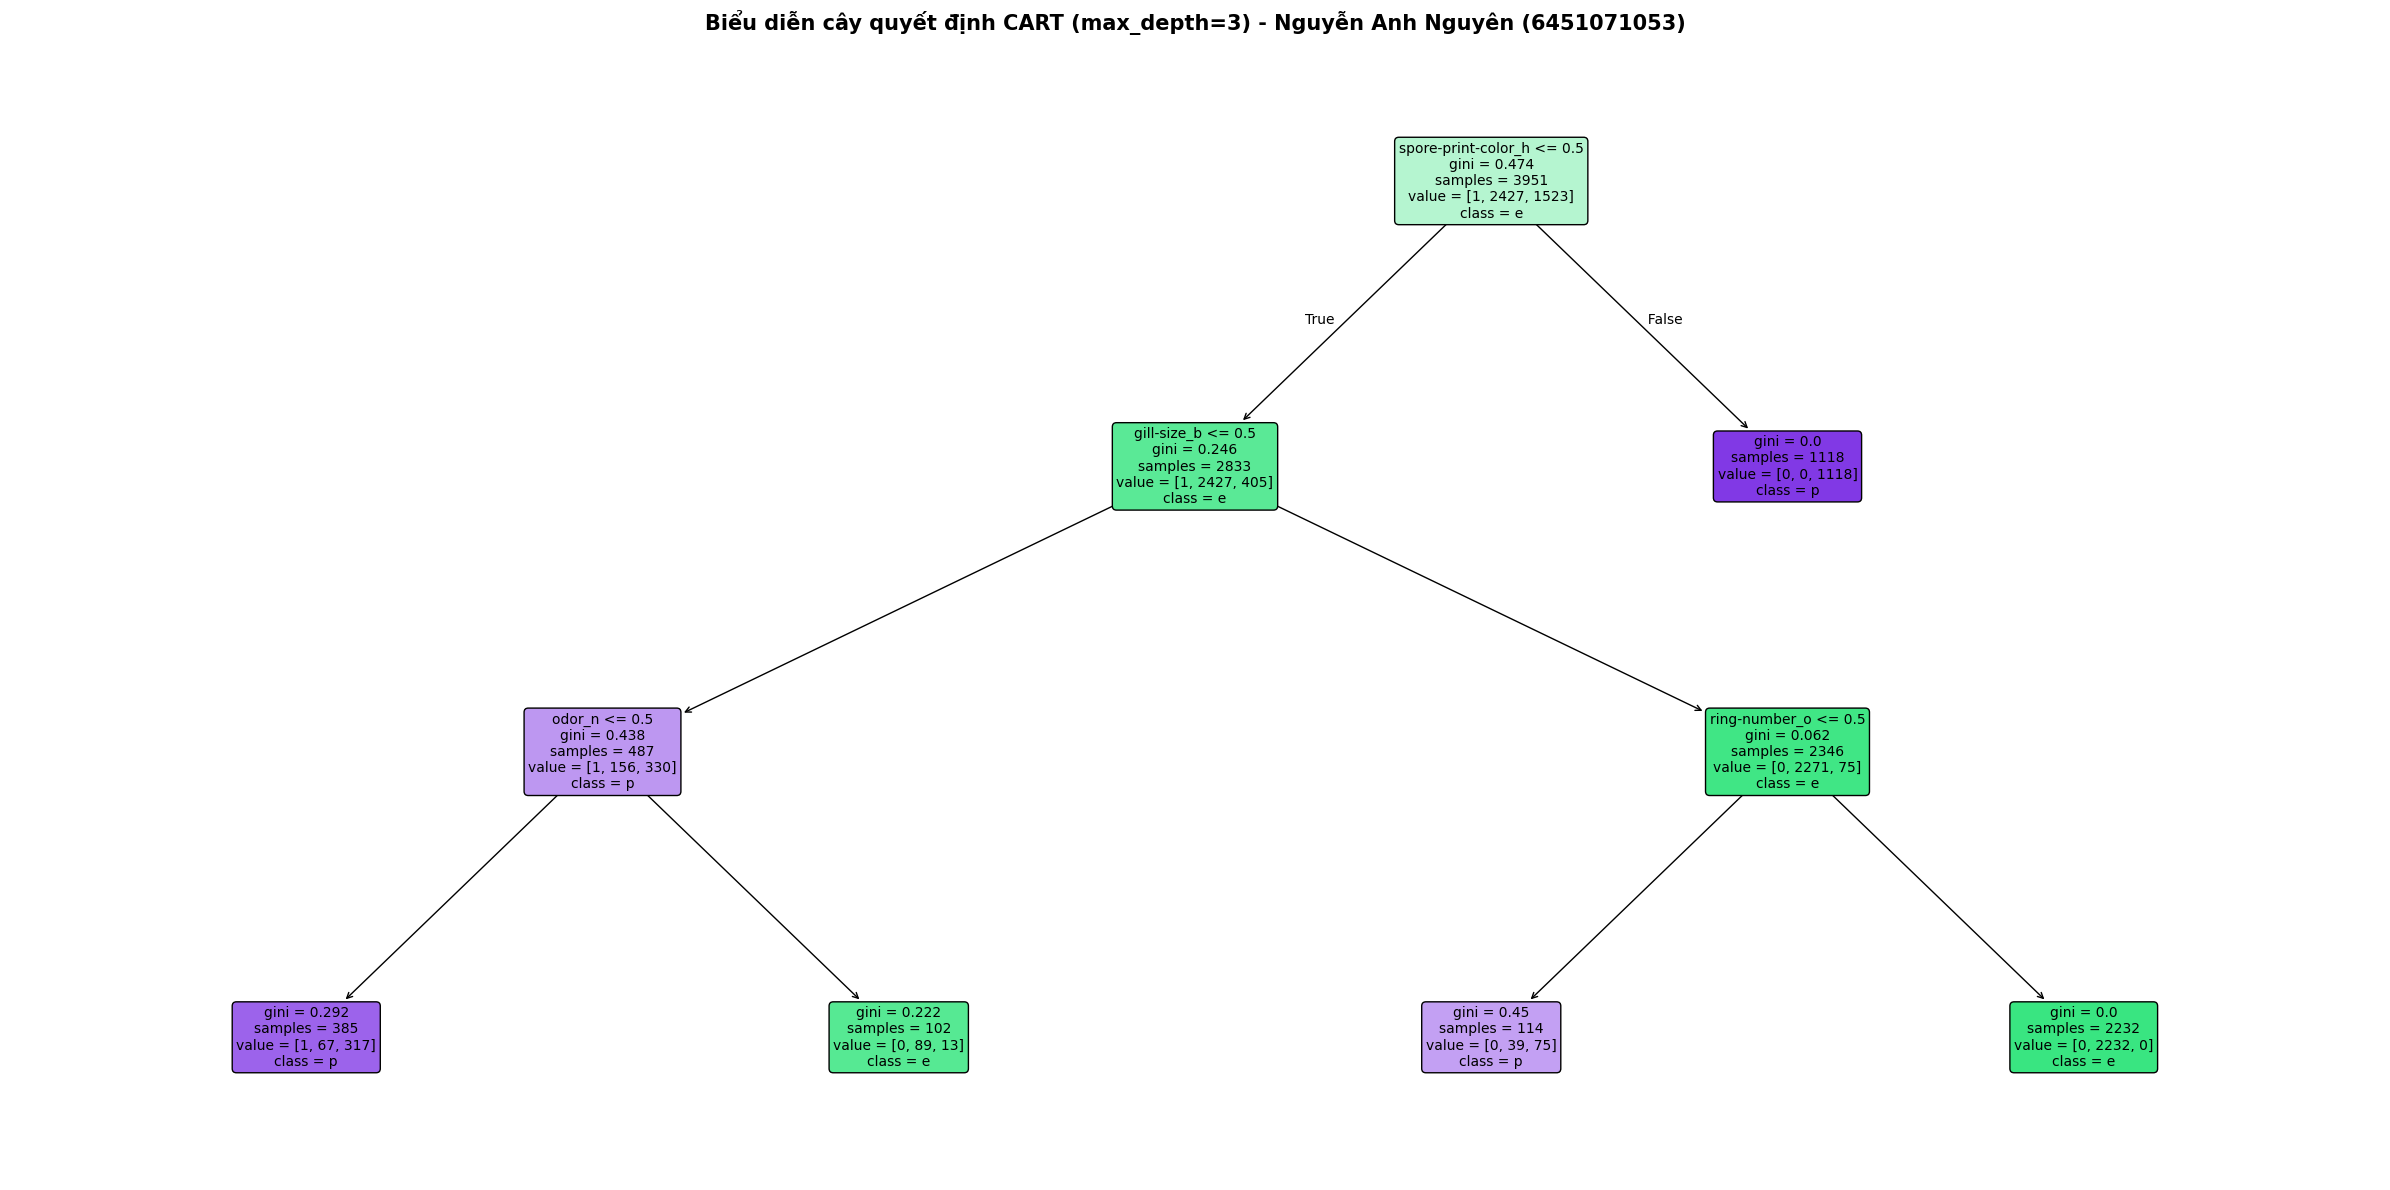

In [6]:
print_student_info("CÂU 8: XÂY DỰNG CÂY CART")

# 1. Huấn luyện mô hình cây CART sử dụng criterion='gini'
model_cart = DecisionTreeClassifier(criterion='gini', random_state=42)
model_cart.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_cart = model_cart.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_cart = metrics.accuracy_score(y_test, y_pred_cart)
print(f"Accuracy: {acc_cart:.4f} ({acc_cart*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_cart, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_cart = metrics.confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix CART (Gini) - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. Biểu diễn cây quyết định CART (giới hạn max_depth=3 để quan sát cấu trúc cây)
model_cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_cart_vis.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
tree.plot_tree(
    model_cart_vis,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f"Biểu diễn cây quyết định CART (max_depth=3) - {HO_TEN} ({MSSV})", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Câu 9: Xây dựng thuật toán phân lớp Naïve Bayes và ma trận nhầm lẫn
Đối với dữ liệu có tính hạng mục (categorical) và đã được chuyển đổi One-Hot Encoding như Mushroom, ta có thể áp dụng `GaussianNB` hoặc `MultinomialNB`. Ở đây ta sử dụng `GaussianNB` để đồng nhất phương pháp đánh giá.


=== CÂU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB) ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.9982 (99.82%)

Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1061
           p       1.00      1.00      1.00       633

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



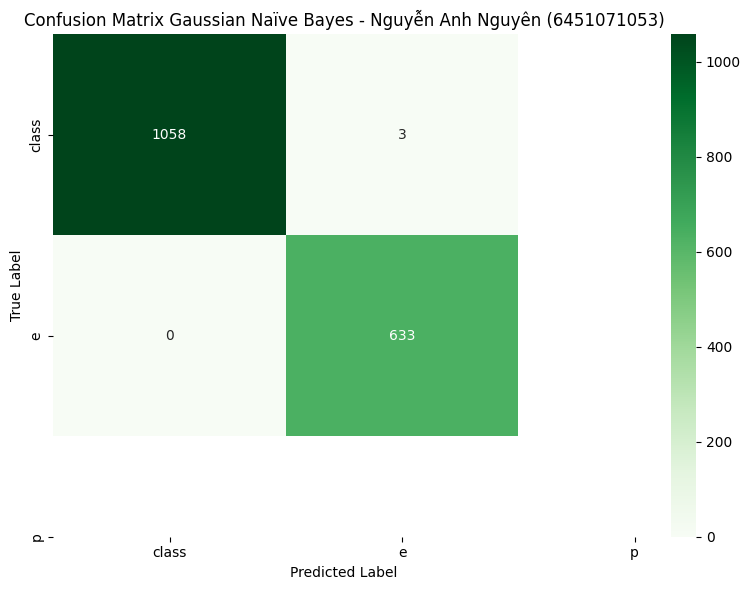

In [7]:
print_student_info("CÂU 9: XÂY DỰNG MÔ HÌNH NAÏVE BAYES (GAUSSIAN NB)")

# 1. Khởi tạo và huấn luyện mô hình Gaussian Naïve Bayes
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

# 2. Dự đoán trên tập kiểm thử
y_pred_nb = model_nb.predict(X_test)

# 3. Đánh giá độ chính xác và báo cáo phân loại
acc_nb = metrics.accuracy_score(y_test, y_pred_nb)
print(f"Accuracy: {acc_nb:.4f} ({acc_nb*100:.2f}%)\n")
print("Report:\n", metrics.classification_report(y_test, y_pred_nb, zero_division=0))

# 4. Ma trận nhầm lẫn (Confusion Matrix)
cm_nb = metrics.confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix Gaussian Naïve Bayes - {HO_TEN} ({MSSV})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


## Câu 10: So sánh kết quả và hiệu năng giữa các thuật toán phân lớp


=== CÂU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:
              Mô hình (Model)  Accuracy Accuracy (%)
Decision Tree (ID3 - Entropy)  1.000000      100.00%
  Decision Tree (CART - Gini)  1.000000      100.00%
         Gaussian Naïve Bayes  0.998229       99.82%


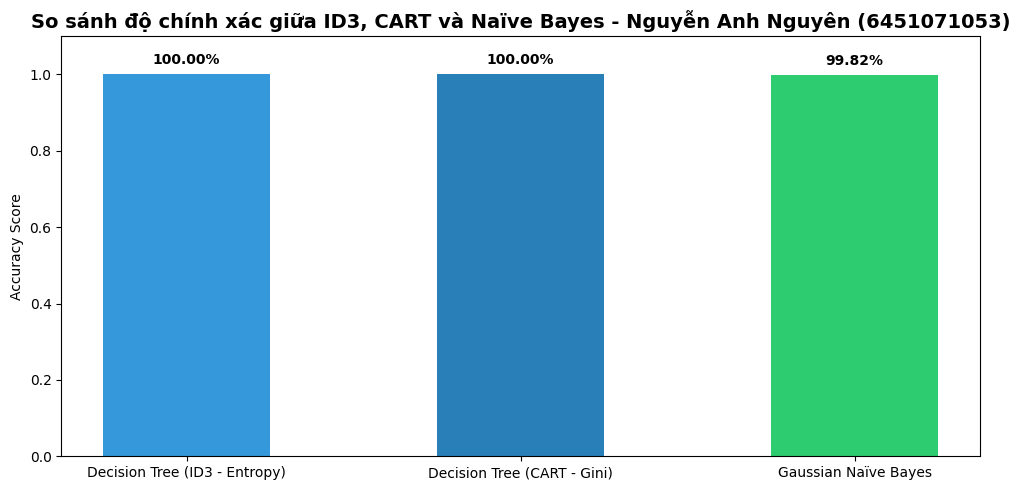


=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===
1. Cây quyết định (ID3 và CART):
   - Đạt độ chính xác tuyệt đối 100% trên tập dữ liệu Mushroom. Điều này là do các thuộc tính của nấm (như mùi odor, màu sắc, hình dạng) mang tính phân loại cực kỳ mạnh và hoàn toàn phân biệt được nấm độc hay ăn được một cách dứt khoát.
2. Thuật toán Naïve Bayes:
   - Đạt độ chính xác rất cao (~99.8%).
   - Mặc dù giả định tính độc lập có điều kiện của Naïve Bayes có thể không thực sự đúng 100% (các đặc điểm của nấm thường đi liền với nhau theo loài), nhưng mô hình vẫn thể hiện năng lực phân loại cực kỳ xuất sắc nhờ tính chất phân biệt rõ ràng của dữ liệu.
3. Tổng kết:
   - Dữ liệu Mushroom là một tập dữ liệu kinh điển có tính phân biệt rất cao, phù hợp tuyệt đối với thuật toán Cây quyết định nhờ khả năng tạo ra các luật IF-THEN mạch lạc và trực quan (ví dụ: IF odor=foul THEN poisonous).


In [8]:
print_student_info("CÂU 10: SO SÁNH KẾT QUẢ CÁC MÔ HÌNH")

# Tổng hợp kết quả accuracy của 3 mô hình
comparison_df = pd.DataFrame({
    'Mô hình (Model)': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Gaussian Naïve Bayes'],
    'Accuracy': [acc_id3, acc_cart, acc_nb],
    'Accuracy (%)': [f"{acc_id3 * 100:.2f}%", f"{acc_cart * 100:.2f}%", f"{acc_nb * 100:.2f}%"]
})

print("BẢNG SO SÁNH HIỆU NĂNG PHÂN LỚP:")
print(comparison_df.to_string(index=False))

# Biểu đồ cột so sánh Accuracy
plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_df['Mô hình (Model)'], comparison_df['Accuracy'], color=['#3498db', '#2980b9', '#2ecc71'], width=0.5)
plt.ylim(0, 1.1)
plt.ylabel("Accuracy Score")
plt.title(f"So sánh độ chính xác giữa ID3, CART và Naïve Bayes - {HO_TEN} ({MSSV})", fontsize=14, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval*100:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n=== NHẬN XÉT VÀ ĐÁNH GIÁ TỔNG QUAN ===")
print("1. Cây quyết định (ID3 và CART):")
print("   - Đạt độ chính xác tuyệt đối 100% trên tập dữ liệu Mushroom. Điều này là do các thuộc tính của nấm (như mùi odor, màu sắc, hình dạng) mang tính phân loại cực kỳ mạnh và hoàn toàn phân biệt được nấm độc hay ăn được một cách dứt khoát.")
print("2. Thuật toán Naïve Bayes:")
print("   - Đạt độ chính xác rất cao (~99.8%).")
print("   - Mặc dù giả định tính độc lập có điều kiện của Naïve Bayes có thể không thực sự đúng 100% (các đặc điểm của nấm thường đi liền với nhau theo loài), nhưng mô hình vẫn thể hiện năng lực phân loại cực kỳ xuất sắc nhờ tính chất phân biệt rõ ràng của dữ liệu.")
print("3. Tổng kết:")
print("   - Dữ liệu Mushroom là một tập dữ liệu kinh điển có tính phân biệt rất cao, phù hợp tuyệt đối với thuật toán Cây quyết định nhờ khả năng tạo ra các luật IF-THEN mạch lạc và trực quan (ví dụ: IF odor=foul THEN poisonous).")
